<a href="https://colab.research.google.com/github/DOHA-BASEM3/DS330-Deep-Learning-Project/blob/main/HAPPPPPPPPPPPPPPAAAAALLLLL_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

sns.set_theme(style="whitegrid")

# Reproducibility
SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [13]:
!pip install -q ucimlrepo

In [14]:
from ucimlrepo import fetch_ucirepo

# Fetch CCPP dataset from UCI
ccpp = fetch_ucirepo(id=294)

# Extract features and target
X = ccpp.data.features
y = ccpp.data.targets

# Combine into one DataFrame
df = pd.concat([X, y], axis=1)

print("CCPP Dataset Downloaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

CCPP Dataset Downloaded Successfully!
Dataset Shape: (9568, 5)


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


In [15]:
TARGET = "PE"

X = df.drop(columns=[TARGET])
y = df[TARGET]

print("Features:", X.columns.tolist())
print("Target:", TARGET)

print("Number of Samples:", len(df))
print("Number of Features:", X.shape[1])
print("Unique Target Values:", y.nunique())

Features: ['AT', 'V', 'AP', 'RH']
Target: PE
Number of Samples: 9568
Number of Features: 4
Unique Target Values: 4836


In [17]:
print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Shape: (9568, 5)

Data Types:
AT    float64
V     float64
AP    float64
RH    float64
PE    float64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      9568 non-null   float64
 1   V       9568 non-null   float64
 2   AP      9568 non-null   float64
 3   RH      9568 non-null   float64
 4   PE      9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
AT,9568.0,19.651231,7.452473,1.81,13.5100,20.345,25.72,37.11
V,9568.0,54.305804,12.707893,25.36,41.7400,52.080,66.54,81.56
AP,9568.0,1013.259078,5.938784,992.89,1009.1000,1012.940,1017.26,1033.30
RH,9568.0,73.308978,14.600269,25.56,63.3275,74.975,84.83,100.16
PE,9568.0,454.365009,17.066995,420.26,439.7500,451.550,468.43,495.76


In [18]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

display(
    missing.sort_values(
        by="Missing Percentage",
        ascending=False
    )
)

,Missing Count,Missing Percentage
AT,0,0.0
V,0,0.0
AP,0,0.0
RH,0,0.0
PE,0,0.0


In [19]:
print("Duplicate Rows:", df.duplicated().sum())

constant_features = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print("Constant Features:", constant_features)

Duplicate Rows: 41
Constant Features: []


In [20]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['AT', 'V', 'AP', 'RH']

Categorical Features:
[]


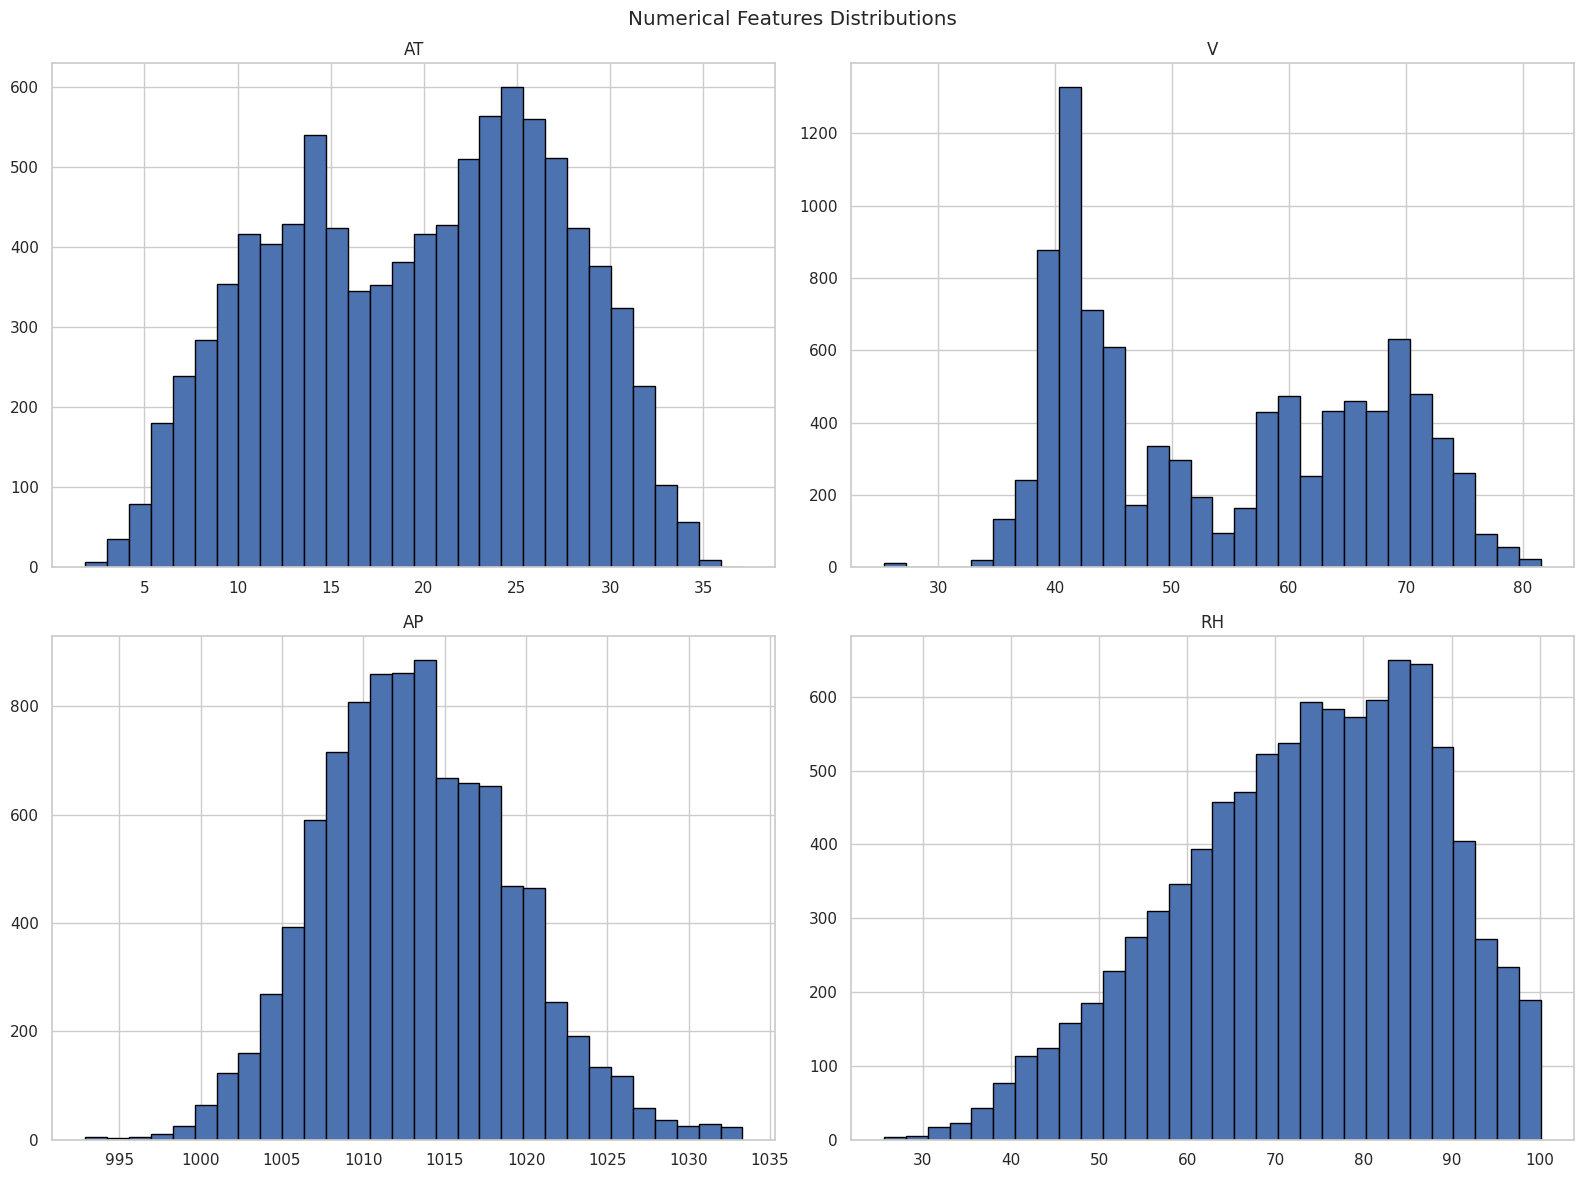

In [21]:
if numerical_features:

    X[numerical_features].hist(
        figsize=(16, 12),
        bins=30,
        edgecolor="black"
    )

    plt.suptitle("Numerical Features Distributions")
    plt.tight_layout()
    plt.show()

In [23]:
for col in categorical_features:

    plt.figure(figsize=(9, 4))

    df[col].value_counts().head(15).plot(
        kind="bar"
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

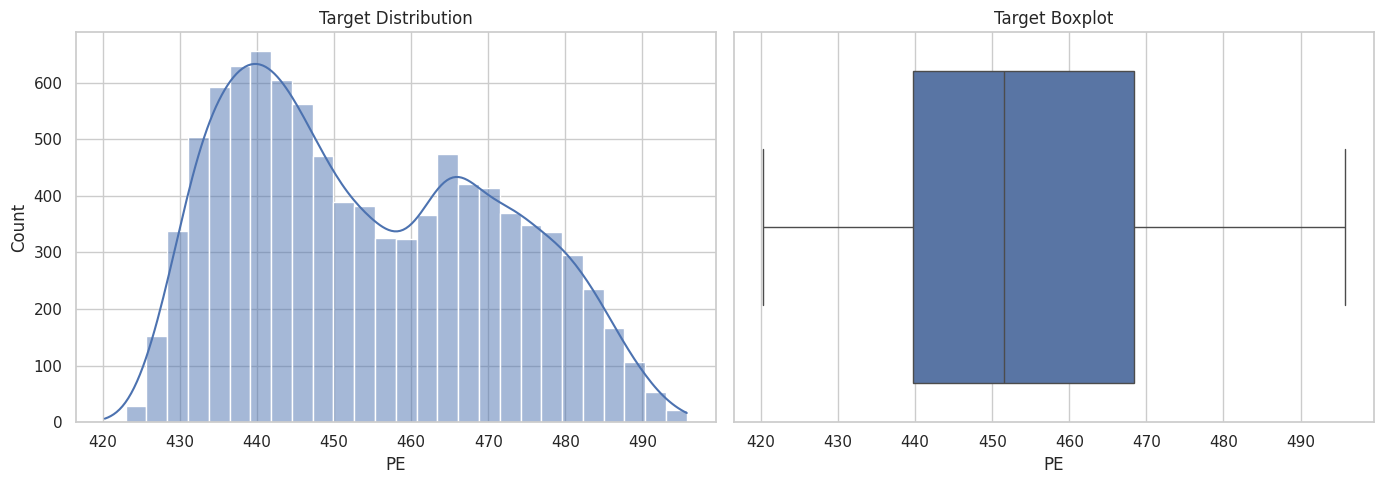

Target Mean: 454.36500940635455
Target Median: 451.54999999999995
Target Std: 17.066994999803423
Target Skewness: 0.3065094354204023


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df[TARGET],
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Target Distribution")

sns.boxplot(
    x=df[TARGET],
    ax=axes[1]
)

axes[1].set_title("Target Boxplot")

plt.tight_layout()
plt.show()

print("Target Mean:", y.mean())
print("Target Median:", y.median())
print("Target Std:", y.std())
print("Target Skewness:", y.skew())

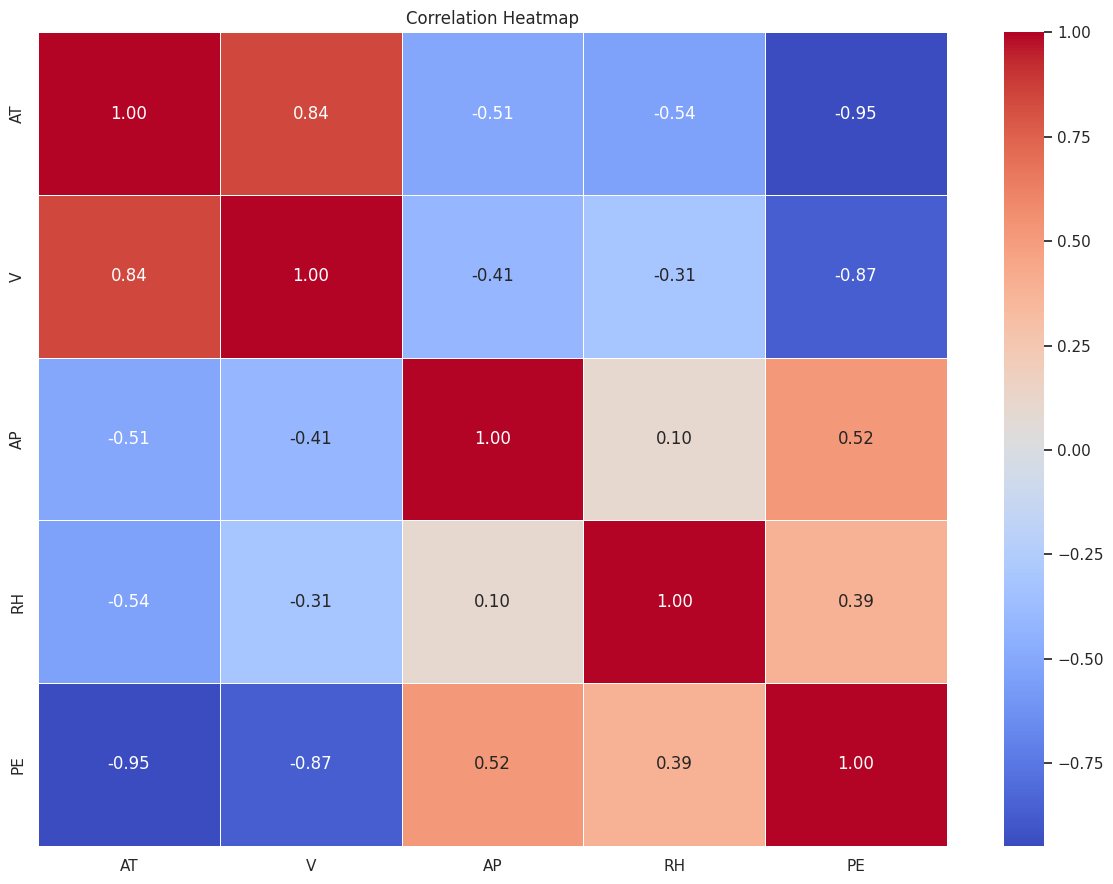

In [25]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

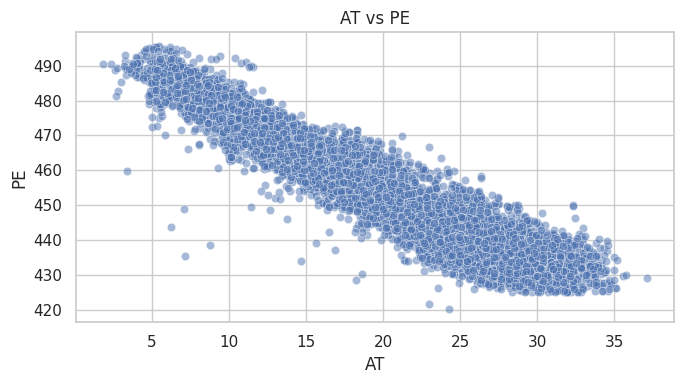

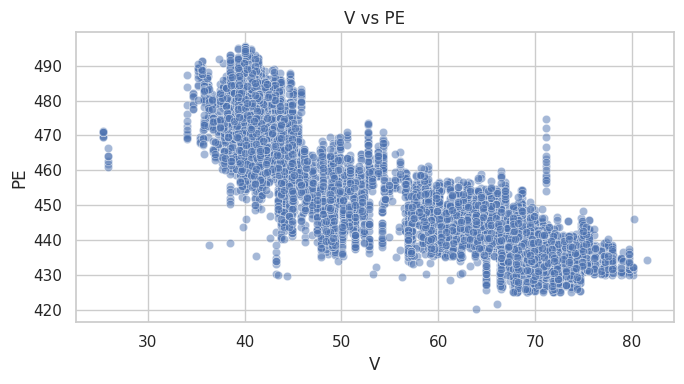

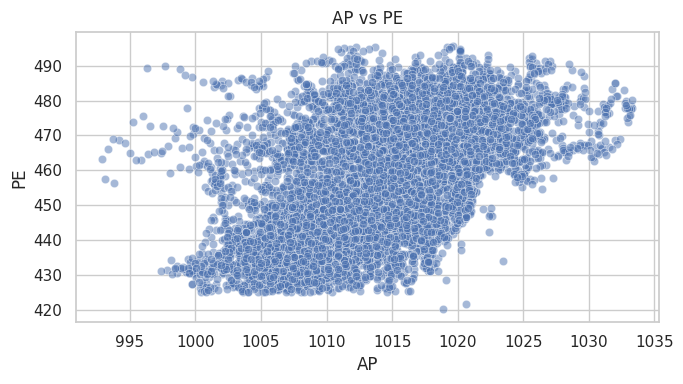

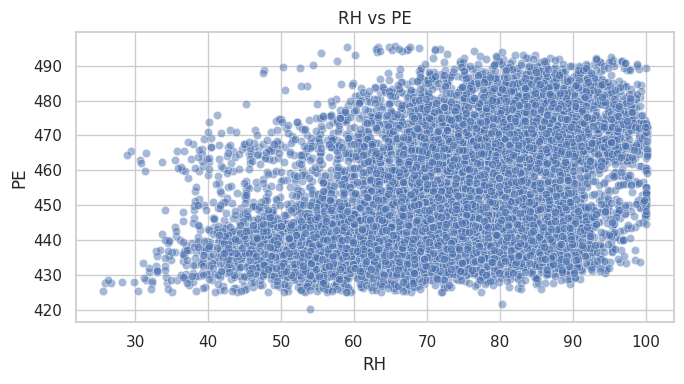

In [26]:
for col in numerical_features:

    plt.figure(figsize=(7, 4))

    sns.scatterplot(
        data=df,
        x=col,
        y=TARGET,
        alpha=0.5
    )

    plt.title(f"{col} vs {TARGET}")
    plt.tight_layout()
    plt.show()

In [27]:
outlier_results = []

for col in numerical_features + [TARGET]:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    outlier_results.append({
        "Feature": col,
        "Outlier Count": count,
        "Outlier Percentage": count / len(df) * 100
    })

display(pd.DataFrame(outlier_results))

,Feature,Outlier Count,Outlier Percentage
0,AT,0,0.000000
1,V,0,0.000000
2,AP,88,0.919732
3,RH,12,0.125418
4,PE,0,0.000000


In [28]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

# First split: 85% train + validation, 15% test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=SEED
)

# Second split: 70% train, 15% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.1764706,
    random_state=SEED
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (6696, 4)
Validation: (1436, 4)
Testing: (1436, 4)


In [29]:
train_df = X_train.copy()
train_df[TARGET] = y_train

print("EDA on training data only")
display(train_df.head())

EDA on training data only


,AT,V,AP,RH,PE
829,30.20,69.59,1008.90,67.32,434.66
7211,21.47,50.12,1009.19,93.68,448.11
5292,24.33,49.16,1003.46,61.04,441.20
4706,24.48,50.23,1017.03,66.89,456.02
7095,28.76,69.48,1008.62,55.86,430.14


In [30]:
train_df = X_train.copy()
train_df[TARGET] = y_train

print("EDA on training data only")
display(train_df.head())

EDA on training data only


,AT,V,AP,RH,PE
829,30.20,69.59,1008.90,67.32,434.66
7211,21.47,50.12,1009.19,93.68,448.11
5292,24.33,49.16,1003.46,61.04,441.20
4706,24.48,50.23,1017.03,66.89,456.02
7095,28.76,69.48,1008.62,55.86,430.14


In [31]:
numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical:", numerical_features)
print("Categorical:", categorical_features)

Numerical: ['AT', 'V', 'AP', 'RH']
Categorical: []


In [32]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and test
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)

Train: (6696, 4)
Validation: (1436, 4)
Test: (1436, 4)


In [33]:
X_train_processed = np.asarray(
    X_train_processed, dtype=np.float32
)

X_val_processed = np.asarray(
    X_val_processed, dtype=np.float32
)

X_test_processed = np.asarray(
    X_test_processed, dtype=np.float32
)

y_mean = y_train.mean()
y_std = y_train.std()

if y_std == 0:
    raise ValueError("Target has zero variance.")

y_train_scaled = (y_train.to_numpy() - y_mean) / y_std
y_val_scaled = (y_val.to_numpy() - y_mean) / y_std

# Test target is prepared for final evaluation only
# Do not use it for model selection
y_test_array = y_test.to_numpy(dtype=np.float32)

X_train_tensor = torch.tensor(
    X_train_processed, dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_processed, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_scaled.reshape(-1, 1), dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val_scaled.reshape(-1, 1), dtype=torch.float32
)

print("Input Features:", X_train_tensor.shape[1])
print("Training Samples:", len(X_train_tensor))

Input Features: 4
Training Samples: 6696


In [34]:
linear_model = LinearRegression()

linear_model.fit(
    X_train_processed,
    y_train
)

linear_train_pred = linear_model.predict(
    X_train_processed
)

linear_val_pred = linear_model.predict(
    X_val_processed
)

linear_train_mse = mean_squared_error(
    y_train,
    linear_train_pred
)

linear_val_mse = mean_squared_error(
    y_val,
    linear_val_pred
)

print("Linear Regression Results")
print("Train MSE:", linear_train_mse)
print("Validation MSE:", linear_val_mse)

Linear Regression Results
Train MSE: 21.13241044321891
Validation MSE: 19.953785008523493


In [39]:
import torch
import torch.nn as nn

# Define Deep Neural Network
class DeepNeuralNetwork(nn.Module):

    def __init__(self, input_size, hidden_layers):

        super(DeepNeuralNetwork, self).__init__()

        layers = []
        previous_size = input_size

        # Hidden Layers
        for hidden_size in hidden_layers:

            layers.append(
                nn.Linear(previous_size, hidden_size)
            )

            layers.append(nn.ReLU())

            previous_size = hidden_size

        # Output Layer
        layers.append(
            nn.Linear(previous_size, 1)
        )

        self.network = nn.Sequential(*layers)

    def forward(self, x):

        output = self.network(x)

        return output


# =====================================
# Create the Model
# =====================================

input_size = X_train_tensor.shape[1]

hidden_layers = [64, 64, 64]

model = DeepNeuralNetwork(
    input_size=input_size,
    hidden_layers=hidden_layers
)

model = model.to(device)


# =====================================
# Display Model Architecture
# =====================================

print("Deep Neural Network Architecture:")
print(model)

print("\nInput Size:", input_size)
print("Hidden Layers:", hidden_layers)
print("Output Size: 1")


# =====================================
# Test Forward Pass
# =====================================

sample_input = X_train_tensor[:5].to(device)

model.eval()

with torch.no_grad():

    predictions = model(sample_input)

print("\nSample Input Shape:", sample_input.shape)

print("\nPredictions:")
print(predictions)

print("\nOutput Shape:", predictions.shape)

Deep Neural Network Architecture:
DeepNeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)

Input Size: 4
Hidden Layers: [64, 64, 64]
Output Size: 1

Sample Input Shape: torch.Size([5, 4])

Predictions:
tensor([[0.0941],
        [0.1006],
        [0.1101],
        [0.0923],
        [0.0867]])

Output Shape: torch.Size([5, 1])


In [41]:
from torch.utils.data import TensorDataset, DataLoader

# Ensure target tensors have shape (N, 1)
y_train_tensor = y_train_tensor.view(-1, 1)
y_val_tensor = y_val_tensor.view(-1, 1)

# Create datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

# Define batch size
batch_size = 64

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 105
Validation batches: 23


In [42]:
baseline_config = {
    "hidden_layers": [64, 64, 64],
    "optimizer_name": "SGD",
    "learning_rate": 0.01,
    "batch_size": 64,
    "loss_name": "MSE",
    "delta": 1.0,
    "epochs": 30
}

baseline_nn = train_model(**baseline_config)

print("Baseline Neural Network")
print("Train MSE:", baseline_nn["train_mse"])
print("Validation MSE:", baseline_nn["val_mse"])
print("Training Time:", baseline_nn["time"])

Baseline Neural Network
Train MSE: 17.92327229147849
Validation MSE: 17.285902106452962
Training Time: 4.368907451629639


In [43]:
experiments = []

# Experiment 1: Baseline NN
experiments.append({
    "Topic": "Baseline",
    "Setting": "Baseline NN",
    "Config": baseline_config.copy()
})


# Topic 1: Learning Rate (8 experiments)
learning_rates = [
    0.0001,
    0.0003,
    0.001,
    0.003,
    0.03,
    0.05,
    0.1,
    0.2
]

for lr in learning_rates:

    config = baseline_config.copy()
    config["learning_rate"] = lr

    experiments.append({
        "Topic": "Learning Rate",
        "Setting": f"lr = {lr}",
        "Config": config
    })


# Topic 2: Optimizer (2 experiments)
optimizers = ["SGD_Momentum", "Adam"]

for opt in optimizers:

    config = baseline_config.copy()
    config["optimizer_name"] = opt

    experiments.append({
        "Topic": "Optimizer",
        "Setting": opt,
        "Config": config
    })


# Topic 3: Batch Size (6 experiments)
batch_sizes = [8, 16, 32, 128, 256, 512]

for batch in batch_sizes:

    config = baseline_config.copy()
    config["batch_size"] = batch

    experiments.append({
        "Topic": "Batch Size",
        "Setting": f"Batch = {batch}",
        "Config": config
    })


# Topic 4: Depth and Width (8 experiments)
architectures = [
    [32],
    [64],
    [128],
    [64, 64],
    [64, 64, 64, 64],
    [128, 128],
    [128, 64, 32],
    [32, 64, 32]
]

for architecture in architectures:

    config = baseline_config.copy()
    config["hidden_layers"] = architecture

    experiments.append({
        "Topic": "Depth and Width",
        "Setting": str(architecture),
        "Config": config
    })


# Topic 5: Loss Function (5 experiments)
loss_settings = [
    ("L1", 1.0),
    ("Huber", 0.5),
    ("Huber", 1.0),
    ("Huber", 2.0),
    ("Huber", 5.0)
]

for loss_name, delta in loss_settings:

    config = baseline_config.copy()
    config["loss_name"] = loss_name
    config["delta"] = delta

    experiments.append({
        "Topic": "Loss Function",
        "Setting": f"{loss_name}, delta={delta}",
        "Config": config
    })


print("Total Experiments:", len(experiments))

assert len(experiments) == 30

Total Experiments: 30


In [44]:
results = []

for i, experiment in enumerate(experiments):

    print(
        f"Running Experiment {i+1}/{len(experiments)}"
    )

    # Reuse the baseline run instead of training it twice
    if experiment["Topic"] == "Baseline":
        result = baseline_nn
    else:
        result = train_model(**experiment["Config"])

    train_mse = result["train_mse"]
    val_mse = result["val_mse"]

    if not np.isfinite(val_mse):
        observation = "Training diverged or produced non-finite values."

    elif val_mse > train_mse * 1.5:
        observation = "Large train-validation performance gap."

    else:
        observation = "Results recorded for comparison."

    results.append({
        "Run": i + 1,
        "Topic": experiment["Topic"],
        "Setting": experiment["Setting"],
        "Train MSE": train_mse,
        "Val MSE": val_mse,
        "Test MSE": np.nan,
        "Time (s)": result["time"],
        "Observation": observation,
        "Config": experiment["Config"],
        "Model": result["model"],
        "History": result["history"]
    })

print("\nAll experiments completed!")

Running Experiment 1/30
Running Experiment 2/30
Running Experiment 3/30
Running Experiment 4/30
Running Experiment 5/30
Running Experiment 6/30
Running Experiment 7/30
Running Experiment 8/30
Running Experiment 9/30
Running Experiment 10/30
Running Experiment 11/30
Running Experiment 12/30
Running Experiment 13/30
Running Experiment 14/30
Running Experiment 15/30
Running Experiment 16/30
Running Experiment 17/30
Running Experiment 18/30
Running Experiment 19/30
Running Experiment 20/30
Running Experiment 21/30
Running Experiment 22/30
Running Experiment 23/30
Running Experiment 24/30
Running Experiment 25/30
Running Experiment 26/30
Running Experiment 27/30
Running Experiment 28/30
Running Experiment 29/30
Running Experiment 30/30

All experiments completed!


In [47]:
results_df = pd.DataFrame(results)

display(results_df)

,Run,Topic,Setting,Train MSE,Val MSE,Test MSE,Time (s),Observation,Config,Model,History
0,1,Baseline,Baseline NN,17.923272,17.285902,NaN,4.368907,Results recorded for comparison.,"{'hidden_layers': [64, 64, 64], 'optimizer_nam...",DeepNeuralNetwork(\n (network): Sequential(\n...,"{'train_mse': [36.52731550983631, 25.987852676..."
1,2,Learning Rate,lr = 0.0001,211.141439,221.675889,NaN,8.346794,Results recorded for comparison.,"{'hidden_layers': [64, 64, 64], 'optimizer_nam...",DeepNeuralNetwork(\n (network): Sequential(\n...,"{'train_mse': [287.75243987781823, 285.6413058..."
2,3,Learning Rate,lr = 0.0003,64.489504,68.706674,NaN,4.639395,Results recorded for comparison.,"{'hidden_layers': [64, 64, 64], 'optimizer_nam...",DeepNeuralNetwork(\n (network): Sequential(\n...,"{'train_mse': [292.2902065865655, 287.69574806..."
3,4,Learning Rate,lr = 0.001,22.949821,21.949624,NaN,4.401184,Results recorded for comparison.,"{'hidden_layers': [64, 64, 64], 'optimizer_nam...",DeepNeuralNetwork(\n (network): Sequential(\n...,"{'train_mse': [275.44828377012925, 251.2465704..."
4,5,Learning Rate,lr = 0.003,18.979157,18.047864,NaN,5.171165,Results recorded for comparison.,"{'hidden_layers': [64, 64, 64], 'optimizer_nam...",DeepNeuralNetwork(\n (network): Sequential(\n...,"{'train_mse': [227.97426049948444, 126.8894923..."
5,6,Learning Rate,lr = 0.03,16.884654,16.124014,NaN,4.255137,Results recorded for comparison.,"{'hidden_layers': [64, 64, 64], 'optimizer_nam...",DeepNeuralNetwork(\n (network): Sequential(\n...,"{'train_mse': [25.270321474324106, 21.00932297..."
6,7,Learning Rate,lr = 0.05,16.784155,16.158526,NaN,4.197055,Results recorded for comparison.,"{'hidden_layers': [64, 64, 64], 'optimizer_nam...",DeepNeuralNetwork(\n (network): Sequential(\n...,"{'train_mse': [23.615780686356715, 19.45764781..."
7,8,Learning Rate,lr = 0.1,18.004933,18.320311,NaN,5.272240,Results recorded for comparison.,"{'hidden_layers': [64, 64, 64], 'optimizer_nam...",DeepNeuralNetwork(\n (network): Sequential(\n...,"{'train_mse': [26.813907577622125, 18.02406017..."
8,9,Learning Rate,lr = 0.2,17.013256,17.107521,NaN,4.413629,Results recorded for comparison.,"{'hidden_layers': [64, 64, 64], 'optimizer_nam...",DeepNeuralNetwork(\n (network): Sequential(\n...,"{'train_mse': [19.578140847773312, 27.42123674..."
9,10,Optimizer,SGD_Momentum,16.522863,16.845381,NaN,4.720669,Results recorded for comparison.,"{'hidden_layers': [64, 64, 64], 'optimizer_nam...",DeepNeuralNetwork(\n (network): Sequential(\n...,"{'train_mse': [20.1972485550315, 18.1646912850..."


In [56]:
valid_results = [
    r for r in results
    if np.isfinite(r["Val MSE"])
]

best_run = min(
    valid_results,
    key=lambda r: r["Val MSE"]
)

best_model = best_run["Model"]
best_config = best_run["Config"]

print("Best Configuration:")
print(best_config)

print("\nBest Validation MSE:")
print(best_run["Val MSE"])

print("\nLinear Regression Validation MSE:")
print(linear_val_mse)

improvement = (
    (linear_val_mse - best_run["Val MSE"])
    / linear_val_mse
) * 100

print("\nImprovement over Linear Regression:")
print(f"{improvement:.2f}%")

Best Configuration:
{'hidden_layers': [64, 64, 64], 'optimizer_name': 'SGD', 'learning_rate': 0.03, 'batch_size': 64, 'loss_name': 'MSE', 'delta': 1.0, 'epochs': 30}

Best Validation MSE:
16.12401435603854

Linear Regression Validation MSE:
19.953785008523493

Improvement over Linear Regression:
19.19%


In [57]:
best_model.eval()

with torch.no_grad():

    test_predictions_scaled = best_model(
        torch.tensor(
            X_test_processed,
            dtype=torch.float32
        ).to(device)
    ).cpu().numpy().flatten()

# Return predictions to original target scale
test_predictions = (
    test_predictions_scaled * y_std + y_mean
)

final_test_mse = mean_squared_error(
    y_test_array,
    test_predictions
)

print("Final Test MSE:", final_test_mse)

Final Test MSE: 16.08015649832857


In [59]:
final_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Deep Neural Network"
    ],

    "Validation MSE": [
        linear_val_mse,
        best_run["Val MSE"]
    ],

    "Test MSE": [
        np.nan,
        final_test_mse
    ]
})

display(final_comparison)

,Model,Validation MSE,Test MSE
0,Linear Regression,19.953785,NaN
1,Deep Neural Network,16.124014,16.080156


In [61]:
print("FINAL MODEL CONFIGURATION")
print("-------------------------")

for key, value in best_config.items():
    print(f"{key}: {value}")

print("\nPerformance")
print("-------------------------")

print("Linear Regression Val MSE:", linear_val_mse)
print("Best DNN Val MSE:", best_run["Val MSE"])
print("Final DNN Test MSE:", final_test_mse)
print(f"Improvement: {improvement:.2f}%")

FINAL MODEL CONFIGURATION
-------------------------
hidden_layers: [64, 64, 64]
optimizer_name: SGD
learning_rate: 0.03
batch_size: 64
loss_name: MSE
delta: 1.0
epochs: 30

Performance
-------------------------
Linear Regression Val MSE: 19.953785008523493
Best DNN Val MSE: 16.12401435603854
Final DNN Test MSE: 16.08015649832857
Improvement: 19.19%
